In [2]:
3+2

5

In [4]:
"""
ジェット追跡 修正版：候補図を先に表示し、番号を選んでからJet 1/2を結ぶ。

上から順に実行する。候補図とCSVは手順1、経路の図とCSVは手順3で保存される。
同じ観測日のPS図の最初の正の等高線を3σimとして、σimを画素面積で換算する。
候補の下限はセル4のDETECTION_SIGMAで指定する。
"""

'\nジェット追跡 修正版：候補図を先に表示し、番号を選んでからJet 1/2を結ぶ。\n\n上から順に実行する。候補図とCSVは手順1、経路の図とCSVは手順3で保存される。\n同じ観測日のPS図の最初の正の等高線を3σimとして、σimを画素面積で換算する。\n候補の下限はセル4のDETECTION_SIGMAで指定する。\n'

In [6]:
# ============================================================
# 使用するライブラリ
# ============================================================
from pathlib import Path
import csv
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from scipy.ndimage import gaussian_filter, maximum_filter
from IPython.display import Image, display


In [8]:
# ============================================================
# 入力FITS・保存先・候補点抽出の設定
# ============================================================
FITS_FILE = Path("/Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/fits/1652+398Q.2025-05-11_mimg.fits")

# ============================================================
# PS図を画像に変換し、ピーク・最低等高線・ビームを自動で読み取る
# ============================================================
import re
import shutil
import subprocess
import tempfile


def read_ps_noise_settings(ps_file):
    """PS図を文字認識し、σimの計算に必要な値を返す。"""
    ps_file = Path(ps_file).expanduser().resolve()

    if not ps_file.is_file():
        raise FileNotFoundError(f"PSファイルがありません: {ps_file}")

    for command in ("gs", "tesseract"):
        if shutil.which(command) is None:
            raise RuntimeError(
                f"{command}が必要です。"
                "インストール後、Jupyterを再起動してください"
            )

    # PSファイル名から観測日を取得
    date = re.search(r"\d{4}-\d{2}-\d{2}", ps_file.name)
    if date is None:
        raise ValueError(
            "PSファイル名にYYYY-MM-DD形式の観測日が必要です"
        )

    # 一時フォルダで画像化と文字認識を行う
    with tempfile.TemporaryDirectory() as tmp:
        png = Path(tmp) / "map.png"

        subprocess.run(
            [
                "gs", "-q", "-dSAFER", "-dBATCH", "-dNOPAUSE",
                "-dFirstPage=1", "-dLastPage=1",
                "-sDEVICE=pnggray", "-r300",
                f"-sOutputFile={png}", str(ps_file),
            ],
            check=True,
            capture_output=True,
            text=True,
        )

        result = subprocess.run(
            [
                "tesseract", str(png), "stdout",
                "-l", "eng", "--psm", "11",
            ],
            check=True,
            capture_output=True,
            text=True,
        )

    # 認識されたマイナス記号を統一
    text = (
        result.stdout
        .replace("−", "-")
        .replace("—", "-")
        .replace("–", "-")
    )

    number = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?"

    peak = re.search(
        rf"Map\s+peak\s*:\s*({number})\s*Jy\s*/\s*beam",
        text,
        re.I,
    )
    contours = re.search(
        r"Contours\s*%\s*:?\s*(.*?)\s*Beam\s+FWHM",
        text,
        re.I | re.S,
    )
    beam = re.search(
        rf"Beam\s+FWHM\s*:\s*({number})\s*[x×]\s*({number})\s*\(mas\)",
        text,
        re.I,
    )

    if not all((peak, contours, beam)):
        raise ValueError(
            "PS図の値を読み取れません。"
            f"文字認識結果を確認してください:\n{text}"
        )

    # 正の等高線のうち、最も低い値を採用
    levels = [
        float(v) for v in re.findall(number, contours.group(1))
    ]
    positive = [v for v in levels if v > 0]

    if not positive:
        raise ValueError("正の等高線を読み取れません")

    peak_value = float(peak.group(1))
    first = min(positive)
    major, minor = sorted(
        [float(beam.group(1)), float(beam.group(2))],
        reverse=True,
    )

    if peak_value <= 0 or minor <= 0:
        raise ValueError("ピークまたはビームの読み取り値が無効です")

    print(
        f"PS読み取り値: peak={peak_value:g} Jy/beam, "
        f"最低等高線={first:g}%, "
        f"beam={major:g} × {minor:g} mas"
    )

    return date.group(), peak_value, first, major, minor


In [10]:
# ============================================================
# Notebookの環境の実行ファイルを検索できるようにする
# ============================================================
import os
import sys
import shutil
from pathlib import Path

conda_bin = str(Path(sys.prefix) / "bin")
os.environ["PATH"] = (
    conda_bin + os.pathsep + os.environ.get("PATH", "")
)

print("Python:", sys.executable)
print("gs:", shutil.which("gs"))
print("tesseract:", shutil.which("tesseract"))

Python: /opt/anaconda3/bin/python
gs: /opt/anaconda3/bin/gs
tesseract: /opt/anaconda3/bin/tesseract


In [12]:
# ===== 使用するPSファイル =====
PS_FILE = Path(
    "/Users/reiya/Desktop/imaging/I-map_PS/1652+398Q.2025-05-11.PS"
)

# ===== 前のエポックの値を残さず、OCRを試す =====
PS_NOISE_EPOCH = None
PS_MAP_PEAK_JY_BEAM = None
PS_FIRST_CONTOUR_PERCENT = None
PS_BEAM_MAJOR_MAS = None
PS_BEAM_MINOR_MAS = None

try:
    (
        PS_NOISE_EPOCH,
        PS_MAP_PEAK_JY_BEAM,
        PS_FIRST_CONTOUR_PERCENT,
        PS_BEAM_MAJOR_MAS,
        PS_BEAM_MINOR_MAS,
    ) = read_ps_noise_settings(PS_FILE)

except (
    ValueError,
    RuntimeError,
    OSError,
    subprocess.SubprocessError,
) as error:
    print(f"PSの自動読み取りに失敗しました:\n{error}")
    print(
        "\n次のPDF表示セルで確認し、"
        "その次の手入力セルを設定してください。"
    )

# ===== σimの計算と保存先 =====
# 最低の正の等高線を3σimとして扱う。
PS_FIRST_CONTOUR_SIGMA = 3.0

OUTPUT_DIR = Path(
    "/Users/reiya/Desktop/imaging/results_fov3000/"
    "Mrk501_2025-05-11/jet_tracking_4"
)

# ===== 画素スケールの設定 =====
# CD行列・CDELTを含まないFITSの場合だけFOVをmasで指定する。
# 通常はNone。指定する場合は画像と画素が正方形であることを想定。
FALLBACK_FOV_MAS = None

# 画素スケールがFITSにない場合用。
# +1はxが増える方向が東、-1は西。
FALLBACK_X_EAST_SIGN = -1

# ===== 表示と候補抽出の設定 =====
DISPLAY_LOG = True
CORE_EXCLUSION_PIXELS = 3

# 平滑化は局所ピークの位置を探すときだけ使用する。
# 閾値判定と出力輝度には元画像を使用する。
SMOOTH_SIGMA_PIXELS = 0.5
LOCAL_MAX_SIZE = 3
MIN_SEPARATION_PIXELS = 2

# 添付Notebookの設定値を維持。
DETECTION_SIGMA = 10
N_CANDIDATES = 30

# ===== 実際の観測周波数 [GHz] =====
# FITSの230 GHz表記ではなく、実際の43 GHzを使用する。
OBS_FREQUENCY_GHZ = 43.0

PSの自動読み取りに失敗しました:
PS図の値を読み取れません。文字認識結果を確認してください:
Clean I map. Array:

BF HKLMNOP

1652+598 at 43.168 GHz 2025 May 11

T

T

T

T

T

T

T

T

T

T

T

T

T

T

L

I

L

|

U

at

0

|

-1

-2

Right Ascension

(mas)

Map center:

RA: 16 53 52.217,

Dec: +39 45 36.608 (2000.0)

Map peak: 0.226 Jy/beam

Contours %: 0.6 1.2 2.4 4.8 9.6 19.2 38.4 76.8

Beam FWHM: 0.33 x 0.15 (mos) at -10°

T

T

!

i

0

0.05

0.1

0.15

0.2

Jy/beam


次のPDF表示セルで確認し、その次の手入力セルを設定してください。


In [14]:
# ============================================================
# 指定したPSをPDFに変換し、Notebook内に表示する
# ============================================================
from pathlib import Path
import base64
import shutil
import subprocess
from IPython.display import HTML, display

ps_path = Path(PS_FILE).expanduser().resolve()

if not ps_path.is_file():
    raise FileNotFoundError(f"PSファイルがありません: {ps_path}")

gs = shutil.which("gs")
if gs is None:
    raise RuntimeError(
        "Ghostscript（gs）が見つかりません。PATH設定セルを実行してください。"
    )

# ============================================================
# PDFの保存先
# ============================================================
PDF_DIR = ps_path.parent / "pdf_preview"
PDF_DIR.mkdir(parents=True, exist_ok=True)
PDF_FILE = PDF_DIR / ps_path.with_suffix(".pdf").name

# ============================================================
# GhostscriptでPSをPDFに変換
# ============================================================
subprocess.run(
    [
        gs,
        "-q",
        "-dSAFER",
        "-dBATCH",
        "-dNOPAUSE",
        "-sDEVICE=pdfwrite",
        f"-sOutputFile={PDF_FILE}",
        str(ps_path),
    ],
    check=True,
    capture_output=True,
    text=True,
)

if not PDF_FILE.is_file() or PDF_FILE.stat().st_size == 0:
    raise RuntimeError("PDFを作成できませんでした。")

print(f"PDFを保存: {PDF_FILE}")

# ============================================================
# PDFをNotebook内に埋め込んで表示
# ============================================================
pdf_base64 = base64.b64encode(
    PDF_FILE.read_bytes()
).decode("ascii")

display(
    HTML(
        f'<iframe src="data:application/pdf;base64,{pdf_base64}" '
        'width="60%" height="700" '
        'style="border:1px solid #ccc;"></iframe>'
    )
)

PDFを保存: /Users/reiya/Desktop/imaging/I-map_PS/pdf_preview/1652+398Q.2025-05-11.pdf


/opt/anaconda3/lib/python3.12/site-packages/IPython/core/display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


In [16]:
# ===== PDFを確認し、必要な場合だけPSの値を手入力する =====
# False：OCRで読み取った値を使用する。
# True ：以下の4つの手入力値を使用する。
#
# OCRが失敗した場合や、読み取り結果を訂正したい場合はTrueにする。
USE_MANUAL_PS = False
#USE_MANUAL_PS = True

# ===== PDFから読み取った値を入力する =====
# Map peak [Jy/beam]
# PDFの単位がmJy/beamの場合は、1000で割って入力する。
#MANUAL_MAP_PEAK_JY_BEAM = None
MANUAL_MAP_PEAK_JY_BEAM = 0.226

# 最低の正の等高線 [%]
# 例えば0.65%なら0.65を入力する。0.0065ではない。
#MANUAL_FIRST_CONTOUR_PERCENT = None
MANUAL_FIRST_CONTOUR_PERCENT = 0.6

# Beam FWHMの長軸と短軸 [mas]
#MANUAL_BEAM_MAJOR_MAS = None
#MANUAL_BEAM_MINOR_MAS = None

MANUAL_BEAM_MAJOR_MAS = 0.33
MANUAL_BEAM_MINOR_MAS = 0.15

# ===== 手入力値を検証して採用する =====
if USE_MANUAL_PS:
    # 入力が無効な場合に、以前の値で解析を続けないようにする。
    PS_NOISE_EPOCH = None
    PS_MAP_PEAK_JY_BEAM = None
    PS_FIRST_CONTOUR_PERCENT = None
    PS_BEAM_MAJOR_MAS = None
    PS_BEAM_MINOR_MAS = None

    values = (
        MANUAL_MAP_PEAK_JY_BEAM,
        MANUAL_FIRST_CONTOUR_PERCENT,
        MANUAL_BEAM_MAJOR_MAS,
        MANUAL_BEAM_MINOR_MAS,
    )

    if any(v is None for v in values):
        raise ValueError(
            "手入力する4つの値をすべて設定してください。"
        )

    values = tuple(float(v) for v in values)

    if not all(np.isfinite(v) and v > 0 for v in values):
        raise ValueError(
            "手入力値はすべて正の有限値にしてください。"
        )

    # 従来どおり、観測日の識別にはPSファイル名を使用する。
    date_match = re.search(
        r"\d{4}-\d{2}-\d{2}",
        Path(PS_FILE).name,
    )

    if date_match is None:
        raise ValueError(
            "PSファイル名にYYYY-MM-DD形式の日付が必要です。"
        )

    PS_NOISE_EPOCH = date_match.group()
    PS_MAP_PEAK_JY_BEAM = values[0]
    PS_FIRST_CONTOUR_PERCENT = values[1]

    # 長軸・短軸を逆に入力した場合も、大きい方を長軸にする。
    PS_BEAM_MAJOR_MAS, PS_BEAM_MINOR_MAS = sorted(
        values[2:],
        reverse=True,
    )

    print("PSの手入力値を採用しました。")

# ===== 解析に必要な値が設定されているか確認 =====
settings = (
    PS_NOISE_EPOCH,
    PS_MAP_PEAK_JY_BEAM,
    PS_FIRST_CONTOUR_PERCENT,
    PS_BEAM_MAJOR_MAS,
    PS_BEAM_MINOR_MAS,
)

if any(v is None for v in settings):
    raise ValueError(
        "PSの値が未設定です。"
        "PDFを確認し、USE_MANUAL_PS = Trueにして、"
        "4つの値を入力後、このセルを再実行してください。"
    )

# ===== 採用する値を表示 =====
print(f"PSファイル名の日付: {PS_NOISE_EPOCH}")
print(f"Map peak: {PS_MAP_PEAK_JY_BEAM:g} Jy/beam")
print(
    f"最低の正の等高線: "
    f"{PS_FIRST_CONTOUR_PERCENT:g}%"
)
print(
    f"Beam FWHM: "
    f"{PS_BEAM_MAJOR_MAS:g} × {PS_BEAM_MINOR_MAS:g} mas"
)

# 日付はPSファイル名由来。
# PS図中の日付との一致を検証する処理は追加していない。

PSの手入力値を採用しました。
PSファイル名の日付: 2025-05-11
Map peak: 0.226 Jy/beam
最低の正の等高線: 0.6%
Beam FWHM: 0.33 × 0.15 mas


In [18]:
# ============================================================
# FITSから2次元の輝度画像とヘッダーを読み込む
# ============================================================
def load_map(path):
    with fits.open(path) as hdul:
        hdu = next((h for h in hdul if h.data is not None), None)
        if hdu is None:
            raise ValueError(f"No image data in {path}")
        header = hdu.header.copy()
        raw = np.asarray(hdu.data, dtype=float)
    image = np.squeeze(raw)
    if image.ndim != 2:
        raise ValueError(f"Expected a 2D image after squeeze, got {raw.shape}: {path}")
    if not np.isfinite(image).any():
        raise ValueError(f"No finite image pixels: {path}")
    return image, header

# ============================================================
# PSの最初の正の等高線からσimを求め、mJy/pixelへ面積換算
# ============================================================
def noise_per_pixel_mjy(mimg_path, mimg_header, image_shape):
    """PS図の0.75% = 3σimからRMSを計算する（候補抽出の目安）。"""
    image_date = re.search(r"\d{4}-\d{2}-\d{2}", mimg_path.name)
    if image_date is None or image_date.group() != PS_NOISE_EPOCH:
        raise ValueError(
            f"PS由来のσimは{PS_NOISE_EPOCH}専用です。"
            "FITS_FILEの観測日を確認してください"
        )
    values = (PS_MAP_PEAK_JY_BEAM, PS_FIRST_CONTOUR_PERCENT,
              PS_FIRST_CONTOUR_SIGMA, PS_BEAM_MAJOR_MAS, PS_BEAM_MINOR_MAS)
    if not all(np.isfinite(v) and v > 0 for v in values):
        raise ValueError("PSのピーク・等高線・σ倍率・ビームは正の有限値にしてください")

    # 最初の正の等高線 [Jy/beam] を3で割ってσimに直す。
    first_contour_jy_beam = PS_MAP_PEAK_JY_BEAM * PS_FIRST_CONTOUR_PERCENT / 100
    sigma_im_mjy_beam = first_contour_jy_beam * 1000 / PS_FIRST_CONTOUR_SIGMA

    # Comrade FITSの画素面積と、PSに記されたCLEANビーム面積を比較する。
    east, north, _ = coordinates_mas(
        [(1, 0), (0, 1)], (0, 0), mimg_header, image_shape
    )
    pixel_area_mas2 = abs(east[0] * north[1] - east[1] * north[0])
    beam_area_mas2 = (np.pi * PS_BEAM_MAJOR_MAS * PS_BEAM_MINOR_MAS
                      / (4 * np.log(2)))
    if not np.isfinite(pixel_area_mas2) or pixel_area_mas2 <= 0:
        raise ValueError("FITSの画素面積が無効です")
    pixels_per_beam = beam_area_mas2 / pixel_area_mas2
    noise_mjy_pixel = sigma_im_mjy_beam / pixels_per_beam

    print(f"PSの最初の正の等高線: {first_contour_jy_beam * 1000:.5g} mJy/beam "
          f"({PS_FIRST_CONTOUR_SIGMA:g}σim)")
    print(f"σim: {sigma_im_mjy_beam:.5g} mJy/beam")
    print(f"ビーム面積: {pixels_per_beam:.3f} 画素 / beam")
    print(f"画素面積換算: {noise_mjy_pixel:.5g} mJy/pixel")
    print(f"候補の下限: {DETECTION_SIGMA * noise_mjy_pixel:.5g} "
          f"mJy/pixel ({DETECTION_SIGMA:g}σim)")
    return noise_mjy_pixel


In [20]:
# ============================================================
# 画像全体から局所的な輝度ピークを候補として抽出
# ============================================================
def find_candidates(image, core, noise_mjy_pixel):
    """平滑化画像で局所ピークを探し、元画像の画素値でnσ判定する。"""
    if LOCAL_MAX_SIZE < 3 or LOCAL_MAX_SIZE % 2 != 1:
        raise ValueError("LOCAL_MAX_SIZEは3以上の奇数にしてください")
    clean = np.where(np.isfinite(image), image, 0.0)
    smooth = gaussian_filter(clean, SMOOTH_SIGMA_PIXELS)
    yy, xx = np.indices(image.shape)
    mask = ((smooth == maximum_filter(smooth, size=LOCAL_MAX_SIZE)) &
            (image >= DETECTION_SIGMA * noise_mjy_pixel) &
            np.isfinite(image) &
            ((xx - core[0]) ** 2 + (yy - core[1]) ** 2 >= CORE_EXCLUSION_PIXELS ** 2))
    ys, xs = np.where(mask)
    ranked = sorted(zip(xs, ys), key=lambda p: (-smooth[p[1], p[0]], p[1], p[0]))
    kept = []
    for x, y in ranked:
        if all(np.hypot(x - q[0], y - q[1]) >= MIN_SEPARATION_PIXELS for q in kept):
            kept.append((int(x), int(y)))
        if len(kept) >= N_CANDIDATES:
            break
    return {i: p for i, p in enumerate(kept, start=1)}

In [22]:
# ============================================================
# FITSヘッダーの画素スケールを使ってコアからの相対位置をmasに変換
# ============================================================
def coordinates_mas(points, core, header, shape):
    """コアからの東西・南北方向のずれをmas単位で返す。"""
    x = np.array([p[0] for p in points], dtype=float)
    y = np.array([p[1] for p in points], dtype=float)
    dx, dy = x - core[0], y - core[1]

    # 添付FITSはRA---SIN/DEC---SINとCD行列を持つが、CRVAL1/2はない。
    # コアからの相対位置にはCRVALやCRPIXは不要。CDの差分だけをmasに直す。
    ra_dec = (str(header.get("CTYPE1", "")).startswith("RA") and
              str(header.get("CTYPE2", "")).startswith("DEC"))
    if ra_dec and all(k in header for k in ("CD1_1", "CD1_2", "CD2_1", "CD2_2")):
        cd = np.array([[header["CD1_1"], header["CD1_2"]],
                       [header["CD2_1"], header["CD2_2"]]], dtype=float)
        source = "FITS CD matrix"
    elif ra_dec and all(k in header for k in ("CDELT1", "CDELT2")):
        pc = np.array([[header.get("PC1_1", 1.0), header.get("PC1_2", 0.0)],
                       [header.get("PC2_1", 0.0), header.get("PC2_2", 1.0)]], dtype=float)
        cd = np.diag([float(header["CDELT1"]), float(header["CDELT2"])]) @ pc
        source = "FITS CDELT/PC"
    else:
        cd = None

    if cd is not None:
        if not np.all(np.isfinite(cd)) or abs(np.linalg.det(cd)) < 1e-30:
            raise ValueError("FITSの画素スケールが無効です。CD/CDELTを確認してください")
        # CUNITが省略されているFITSでは、FITS標準どおりdegとして扱う。
        units = [str(header.get(k, "deg")).strip().lower() for k in ("CUNIT1", "CUNIT2")]
        factors = {"deg": 3_600_000.0, "degree": 3_600_000.0,
                   "rad": 180.0 / np.pi * 3_600_000.0,
                   "mas": 1.0, "arcsec": 1_000.0}
        if any(u not in factors for u in units):
            raise ValueError(f"未対応のFITS角度単位です: {units}")
        east = (cd[0, 0] * dx + cd[0, 1] * dy) * factors[units[0]]
        north = (cd[1, 0] * dx + cd[1, 1] * dy) * factors[units[1]]
        return east, north, source

    if FALLBACK_FOV_MAS is None or FALLBACK_FOV_MAS <= 0 or shape[0] != shape[1]:
        raise ValueError("FITSに画素スケールがありません。FALLBACK_FOV_MASを指定してください")
    step = FALLBACK_FOV_MAS / shape[1]
    return dx * step * FALLBACK_X_EAST_SIGN, dy * step, "FOV fallback"


In [24]:
# ============================================================
# Jy/pixel → 観測者系のRayleigh–Jeans輝度温度 [K]
# ============================================================
def brightness_temperature_factor(header, shape):
    if OBS_FREQUENCY_GHZ is not None:
        frequency_hz = float(OBS_FREQUENCY_GHZ) * 1e9
        frequency_source = "OBS_FREQUENCY_GHZ"
    else:
        frequency_hz = None
        frequency_source = None
        for axis in range(1, int(header.get("NAXIS", 2)) + 1):
            if str(header.get(f"CTYPE{axis}", "")).strip().upper().startswith("FREQ"):
                value = header.get(f"CRVAL{axis}")
                if value is not None:
                    freq_unit = str(header.get(f"CUNIT{axis}", "Hz")).strip().lower()
                    scales = {"hz": 1.0, "khz": 1e3, "mhz": 1e6, "ghz": 1e9}
                    if freq_unit not in scales:
                        raise ValueError(f"未対応の周波数単位: {freq_unit}")
                    frequency_hz = float(value) * scales[freq_unit]
                    frequency_source = f"CRVAL{axis}"
                    break
        if frequency_hz is None:
            for key in ("FREQ", "OBSFREQ", "RF"):
                if header.get(key) is not None:
                    frequency_hz = float(header[key])  # これらのキーはHzを想定
                    frequency_source = key
                    break
        if frequency_hz is None:
            raise ValueError("FITSに観測周波数がありません。OBS_FREQUENCY_GHZに実際の周波数（例: 43.0）を指定してください。RESTFRQは観測周波数として自動使用しません。")
    if not np.isfinite(frequency_hz) or frequency_hz <= 0:
        raise ValueError("観測周波数は正の有限値にしてください")
    east, north, _ = coordinates_mas([(1, 0), (0, 1)], (0, 0), header, shape)
    pixel_area_mas2 = abs(east[0] * north[1] - east[1] * north[0])
    mas_to_rad = np.pi / (180.0 * 3_600_000.0)
    omega_pixel_sr = pixel_area_mas2 * mas_to_rad ** 2
    if not np.isfinite(omega_pixel_sr) or omega_pixel_sr <= 0:
        raise ValueError("画素の立体角が無効です")
    from astropy.constants import c, k_B
    # 1 mJy = 1e-29 W m^-2 Hz^-1
    factor = c.value ** 2 / (2 * k_B.value * frequency_hz ** 2) * 1e-29 / omega_pixel_sr
    print(f"観測周波数: {frequency_hz / 1e9:.6g} GHz ({frequency_source})")
    print(f"画素立体角: {omega_pixel_sr:.6g} sr; 1 mJy/pixel = {factor:.6g} K")
    return factor

# ============================================================
# 東西・南北方向のずれから位置角（PA）を計算
# ============================================================
def pa_deg(east, north):
    """位置角を返す。北が0°、東が90°で、天球上で時計回りに測る。"""
    return float(np.degrees(np.arctan2(east, north)) % 360.0)

In [26]:
# ============================================================
# 候補点と経路の図を保存するための背景画像を作る
# コアを(0, 0)とし、画像全体を東西・南北のmas座標で描く
# ============================================================
def make_figure(image, unit, core, header):
    ny, nx = image.shape
    x_edges, y_edges = np.meshgrid(np.arange(nx + 1) - 0.5,
                                   np.arange(ny + 1) - 0.5)
    edge_pixels = list(zip(x_edges.ravel(), y_edges.ravel()))
    east_edges, north_edges, _ = coordinates_mas(edge_pixels, core, header, image.shape)
    east_edges = east_edges.reshape(x_edges.shape)
    north_edges = north_edges.reshape(y_edges.shape)

    finite = image[np.isfinite(image)]
    hi = float(np.max(finite))
    fig, ax = plt.subplots(figsize=(9, 8))
    if DISPLAY_LOG and hi > 0 and np.any(finite < hi):
        positive = finite[finite > 0]
        lo = max(float(np.min(positive)), hi * 1e-5)
        if lo < hi:
            im = ax.pcolormesh(east_edges, north_edges, image, shading="flat",
                               cmap="inferno", norm=LogNorm(vmin=lo, vmax=hi), rasterized=True)
        else:
            im = ax.pcolormesh(east_edges, north_edges, image, shading="flat",
                               cmap="inferno", vmin=0, vmax=hi, rasterized=True)
    else:
        lo = float(np.min(finite))
        im = ax.pcolormesh(east_edges, north_edges, image, shading="flat",
                           cmap="inferno", vmin=lo, vmax=hi, rasterized=True)
    fig.colorbar(im, ax=ax, label=unit)
    ax.set(xlabel="Relative Right Ascension (mas)",
           ylabel="Relative Declination (mas)")
    ax.set_xlim(float(np.max(east_edges)), float(np.min(east_edges)))
    ax.set_ylim(float(np.min(north_edges)), float(np.max(north_edges)))
    ax.set_aspect("equal")
    fig.tight_layout()
    return fig, ax


In [28]:
# ============================================================
# 候補点一覧を画像とCSVに保存し、指定番号だけを経路として結ぶ
# ============================================================
def process(path, mode):
    image, header = load_map(path)
    date_match = re.search(r"\d{4}-\d{2}-\d{2}", path.name)
    if date_match is None:
        raise ValueError(f"FITSのファイル名から観測日を読み取れません: {path.name}")
    observation_date = date_match.group()
    input_unit = str(header.get("BUNIT", "")).strip()

    # Jy/pixelをmJy/pixelへ換算
    if input_unit.lower() == "jy/pixel":
        image = image * 1000.0
        unit = "mJy/pixel"
    elif input_unit == "mJy/pixel":
        unit = input_unit
    else:
        raise ValueError(
            f"想定外の輝度単位です: {input_unit!r}。BUNITを確認してください"
        )

    # 候補判定はmJy/pixel、画像表示は輝度温度[K]で行う
    temperature_factor = brightness_temperature_factor(header, image.shape)
    temperature_image = image * temperature_factor
    temperature_unit = "Brightness temperature (K)"

    core_index = np.argmax(np.where(np.isfinite(image), image, -np.inf))
    core_y, core_x = np.unravel_index(core_index, image.shape)
    core = (int(core_x), int(core_y))

    noise_mjy_pixel = noise_per_pixel_mjy(path, header, image.shape)
    candidates = find_candidates(image, core, noise_mjy_pixel)
    if not candidates:
        print(
            f"{DETECTION_SIGMA:g}σim相当以上の候補はありません。"
            "PSの設定値・ビーム・観測日を確認してください"
        )

    points = list(candidates.values())
    east, north, source = coordinates_mas(points, core, header, image.shape)

    if mode not in {"candidates", "selected"}:
        raise ValueError("modeは'candidates'または'selected'にしてください")

    # ============================================================
    # 候補番号付きの画像とCSVを保存・表示
    # ============================================================
    if mode == "candidates":
        fig, ax = make_figure(
            temperature_image, temperature_unit, core, header
        )
        ax.scatter(
            0.0, 0.0, marker="x", s=130,
            c="black", linewidths=2, label="Core"
        )
        ax.annotate(
            "Core", (0.0, 0.0), xytext=(7, 7),
            textcoords="offset points", color="white"
        )

        candidate_dir = OUTPUT_DIR / "01_brightness_candidates"
        candidate_dir.mkdir(parents=True, exist_ok=True)
        candidate_csv = candidate_dir / f"{observation_date}.csv"

        with candidate_csv.open(
            "w", newline="", encoding="utf-8-sig"
        ) as f:
            w = csv.writer(f)
            w.writerow([
                "epoch_file", "candidate_id", "pixel_x", "pixel_y",
                "peak_brightness_mJy_per_pixel", "brightness_unit",
                "east_mas", "north_mas", "core_distance_mas",
                "core_PA_deg", "coordinate_source",
                "noise_mJy_per_pixel", "peak_SNR",
                "peak_brightness_temperature_K"
            ])

            for idx, (x, y) in candidates.items():
                e, n = float(east[idx - 1]), float(north[idx - 1])
                w.writerow([
                    path.name, idx, x, y, image[y, x], unit, e, n,
                    np.hypot(e, n), pa_deg(e, n), source,
                    noise_mjy_pixel, image[y, x] / noise_mjy_pixel,
                    temperature_image[y, x]
                ])
                ax.scatter(
                    e, n, c="cyan", s=35,
                    edgecolors="black", zorder=4
                )
                ax.annotate(
                    f"{idx}", (e, n), xytext=(5, 5),
                    textcoords="offset points",
                    color="white", fontsize=9, weight="bold"
                )
                print(
                    f"候補{idx:2d}: pixel=({x:2d},{y:2d}) "
                    f"T_B={temperature_image[y, x]:.5g} K, "
                    f"I/noise={image[y, x] / noise_mjy_pixel:.2f}, "
                    f"(東,北)=({e:+.3f},{n:+.3f}) mas"
                )

        ax.set_title(f"{path.name} | brightness candidates")
        ax.legend(loc="upper right")

        candidate_png = OUTPUT_DIR / f"{observation_date}_candidate_numbers.png"
        fig.savefig(candidate_png, dpi=200, bbox_inches="tight")
        plt.close(fig)

        if not candidate_png.is_file():
            raise RuntimeError(f"候補図を保存できませんでした: {candidate_png}")

        print(f"候補図を保存: {candidate_png.resolve()}")
        print(f"候補CSVを保存: {candidate_csv.resolve()}")
        display(Image(filename=str(candidate_png), width=700))
        return

    # ============================================================
    # 指定した最大4経路を確認
    # ============================================================
    selections = {
        "Jet 1": JET1_IDS,
        "Jet 3": JET3_IDS,
        "Jet 2": JET2_IDS,
        "Jet 4": JET4_IDS,
    }

    for jet, ids in selections.items():
        if len(ids) != len(set(ids)) or any(i not in candidates for i in ids):
            raise ValueError(
                f"{jet}の番号が重複、または候補一覧に存在しません: {ids}"
            )

    if not any(selections.values()):
        raise ValueError(
            "先に候補図を見て"
            "JET1_IDS / JET3_IDS / JET2_IDS / JET4_IDSへ番号を入力してください"
        )

    # ============================================================
    # 経路ごとの色と保存先
    # ============================================================
    fig, ax = make_figure(
        temperature_image, temperature_unit, core, header
    )
    ax.scatter(
        0.0, 0.0, marker="x", s=130,
        c="black", linewidths=2, label="Core"
    )

    colors = {
        "Jet 1": "cyan",
        "Jet 3": "magenta",
        "Jet 2": "lime",
        "Jet 4": "orange",
    }

    points_dir = OUTPUT_DIR / "02_selected_jet_points"
    segments_dir = OUTPUT_DIR / "03_jet_segment_angles"
    points_dir.mkdir(parents=True, exist_ok=True)
    segments_dir.mkdir(parents=True, exist_ok=True)

    points_csv = points_dir / f"{observation_date}.csv"
    segments_csv = segments_dir / f"{observation_date}.csv"

    # ============================================================
    # 番号なしの経路画像を作成し、点と区間のCSVを保存
    # ============================================================
    with points_csv.open("w", newline="", encoding="utf-8-sig") as fp, \
         segments_csv.open("w", newline="", encoding="utf-8-sig") as fs:
        wp, ws = csv.writer(fp), csv.writer(fs)

        wp.writerow([
            "epoch_file", "jet", "order", "candidate_id",
            "pixel_x", "pixel_y", "peak_brightness_mJy_per_pixel",
            "brightness_unit", "east_mas", "north_mas",
            "core_distance_mas", "core_PA_deg", "coordinate_source",
            "noise_mJy_per_pixel", "peak_SNR",
            "peak_brightness_temperature_K"
        ])
        ws.writerow([
            "epoch_file", "jet", "from_id", "to_id",
            "length_mas", "PA_deg",
            "delta_east_mas", "delta_north_mas"
        ])

        for jet, ids in selections.items():
            if not ids:
                continue

            color = colors[jet]
            coords = [(0.0, 0.0)] + [
                (float(east[i - 1]), float(north[i - 1]))
                for i in ids
            ]
            ax.plot(
                [p[0] for p in coords],
                [p[1] for p in coords],
                "-o", color=color, linewidth=1.5,
                markersize=5, label=jet
            )

            previous_e, previous_n, previous_label = 0.0, 0.0, "Core"

            for k, cid in enumerate(ids, start=1):
                x, y = candidates[cid]
                e, n = float(east[cid - 1]), float(north[cid - 1])
                de, dn = e - previous_e, n - previous_n
                segment_pa = pa_deg(de, dn)

                wp.writerow([
                    path.name, jet, k, cid, x, y, image[y, x], unit,
                    e, n, np.hypot(e, n), pa_deg(e, n), source,
                    noise_mjy_pixel, image[y, x] / noise_mjy_pixel,
                    temperature_image[y, x]
                ])
                ws.writerow([
                    path.name, jet, previous_label, cid,
                    np.hypot(de, dn), segment_pa, de, dn
                ])
                previous_e, previous_n, previous_label = e, n, cid

    ax.set_title(f"{path.name} | selected Jet 1 / Jet 3 / Jet 2 / Jet 4")
    ax.legend(loc="upper right")

    jet_png = OUTPUT_DIR / f"{observation_date}_jet_lines_no_numbers.png"
    fig.savefig(jet_png, dpi=200, bbox_inches="tight")
    plt.close(fig)

    for saved in (jet_png, points_csv, segments_csv):
        if not saved.is_file():
            raise RuntimeError(f"出力を保存できませんでした: {saved}")
        print(f"保存: {saved.resolve()}")

    display(Image(filename=str(jet_png), width=700))

In [30]:
# ============================================================
# FITSの確認・保存先の作成・指定された処理の実行
# ============================================================
def main(mode):
    if not FITS_FILE.is_file():
        raise FileNotFoundError(f"FITS file not found: {FITS_FILE}")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    process(FITS_FILE, mode=mode)
    print(f"保存先フォルダ: {OUTPUT_DIR.resolve()}")


観測周波数: 43 GHz (OBS_FREQUENCY_GHZ)
画素立体角: 2.29535e-20 sr; 1 mJy/pixel = 7.66905e+08 K
PSの最初の正の等高線: 1.356 mJy/beam (3σim)
σim: 0.452 mJy/beam
ビーム面積: 57.434 画素 / beam
画素面積換算: 0.0078699 mJy/pixel
候補の下限: 0.078699 mJy/pixel (10σim)
候補 1: pixel=(57,52) T_B=5.7048e+09 K, I/noise=945.22, (東,北)=(-0.187,+0.062) mas
候補 2: pixel=(36,49) T_B=5.2809e+08 K, I/noise=87.50, (東,北)=(+0.469,-0.031) mas
候補 3: pixel=(45,55) T_B=4.7099e+08 K, I/noise=78.04, (東,北)=(+0.187,+0.156) mas
候補 4: pixel=(42,36) T_B=2.7236e+08 K, I/noise=45.13, (東,北)=(+0.281,-0.437) mas
候補 5: pixel=(26,21) T_B=1.1659e+08 K, I/noise=19.32, (東,北)=(+0.781,-0.906) mas
候補 6: pixel=(36,24) T_B=1.0739e+08 K, I/noise=17.79, (東,北)=(+0.469,-0.812) mas
候補 7: pixel=(39,28) T_B=1.0746e+08 K, I/noise=17.80, (東,北)=(+0.375,-0.687) mas
候補 8: pixel=(37,40) T_B=1.0543e+08 K, I/noise=17.47, (東,北)=(+0.437,-0.312) mas
候補 9: pixel=(29,44) T_B=1.0026e+08 K, I/noise=16.61, (東,北)=(+0.687,-0.187) mas
候補10: pixel=(36,38) T_B=9.8614e+07 K, I/noise=16.34, (東,北)=(+0

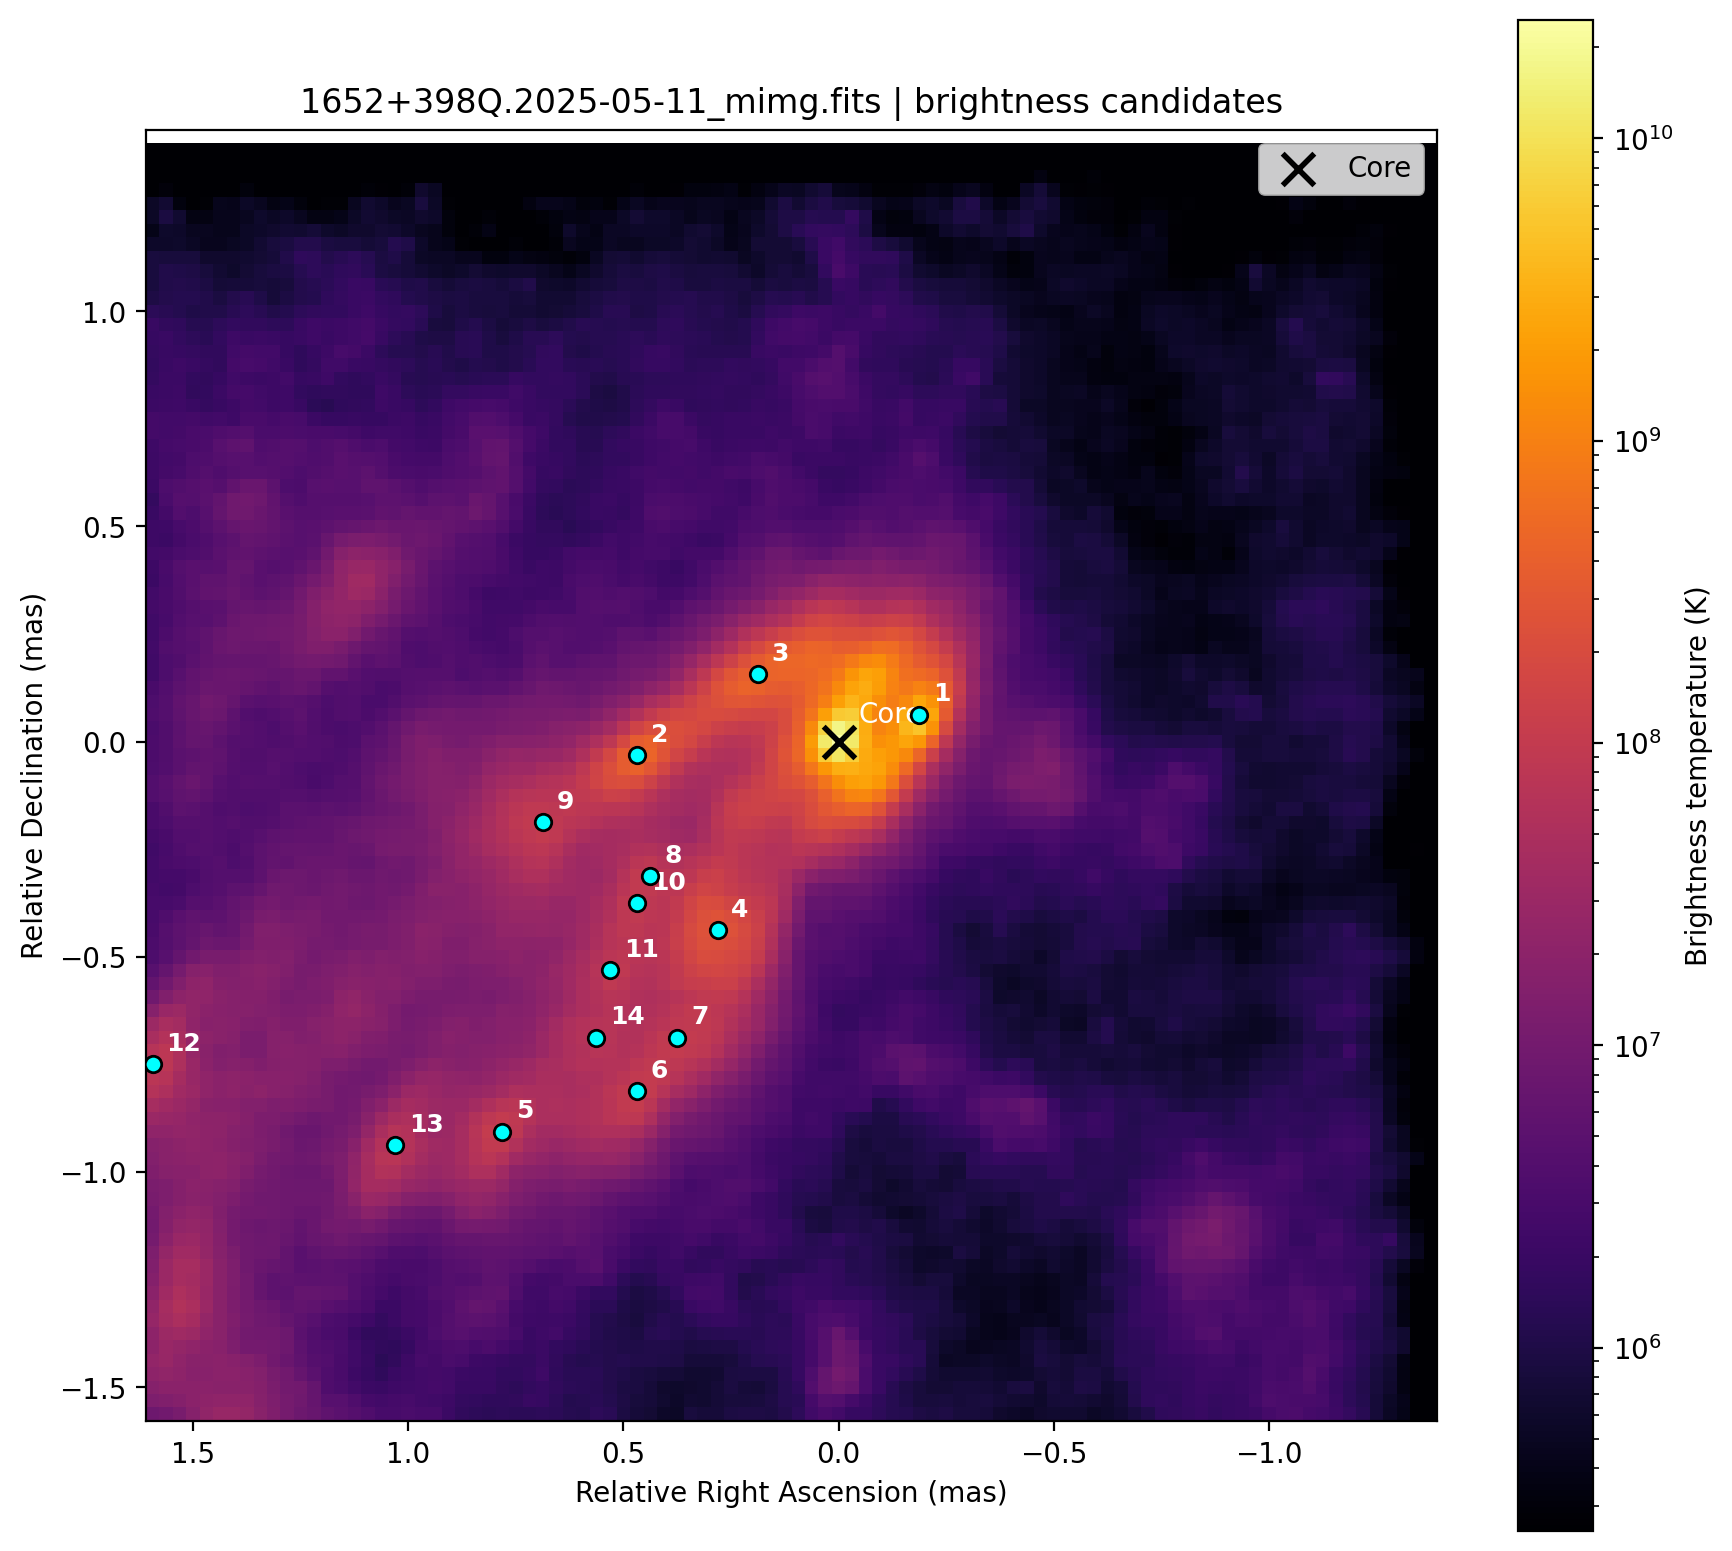

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4


In [32]:
# ============================================================
# 手順1：候補点の図とCSVを保存し、図をここに表示
# ============================================================
main(mode="candidates")


In [34]:
# ============================================================
# 手順2：候補番号を指定し、Jet1の2経路とJet2の計4経路を結ぶ
# コアから下流へ結びたい順番で記入する
# 分岐前の共通部分はJet1・Jet3の両方に同じ番号を記入できる
# ============================================================
JET1_IDS = [4,7,6,5,13]                    # Jet1：従来のJet1の経路
JET3_IDS = [8,10,11,14,5]                   # Jet3：分裂したJet1の片方

JET2_IDS = [1,3,2,9]                # Jet2：従来の経路
JET4_IDS = []                   # Jet4: Jet2 -> Jet1へ横切る構造


観測周波数: 43 GHz (OBS_FREQUENCY_GHZ)
画素立体角: 2.29535e-20 sr; 1 mJy/pixel = 7.66905e+08 K
PSの最初の正の等高線: 1.356 mJy/beam (3σim)
σim: 0.452 mJy/beam
ビーム面積: 57.434 画素 / beam
画素面積換算: 0.0078699 mJy/pixel
候補の下限: 0.078699 mJy/pixel (10σim)
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4/2025-05-11_jet_lines_no_numbers.png
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4/02_selected_jet_points/2025-05-11.csv
保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4/03_jet_segment_angles/2025-05-11.csv


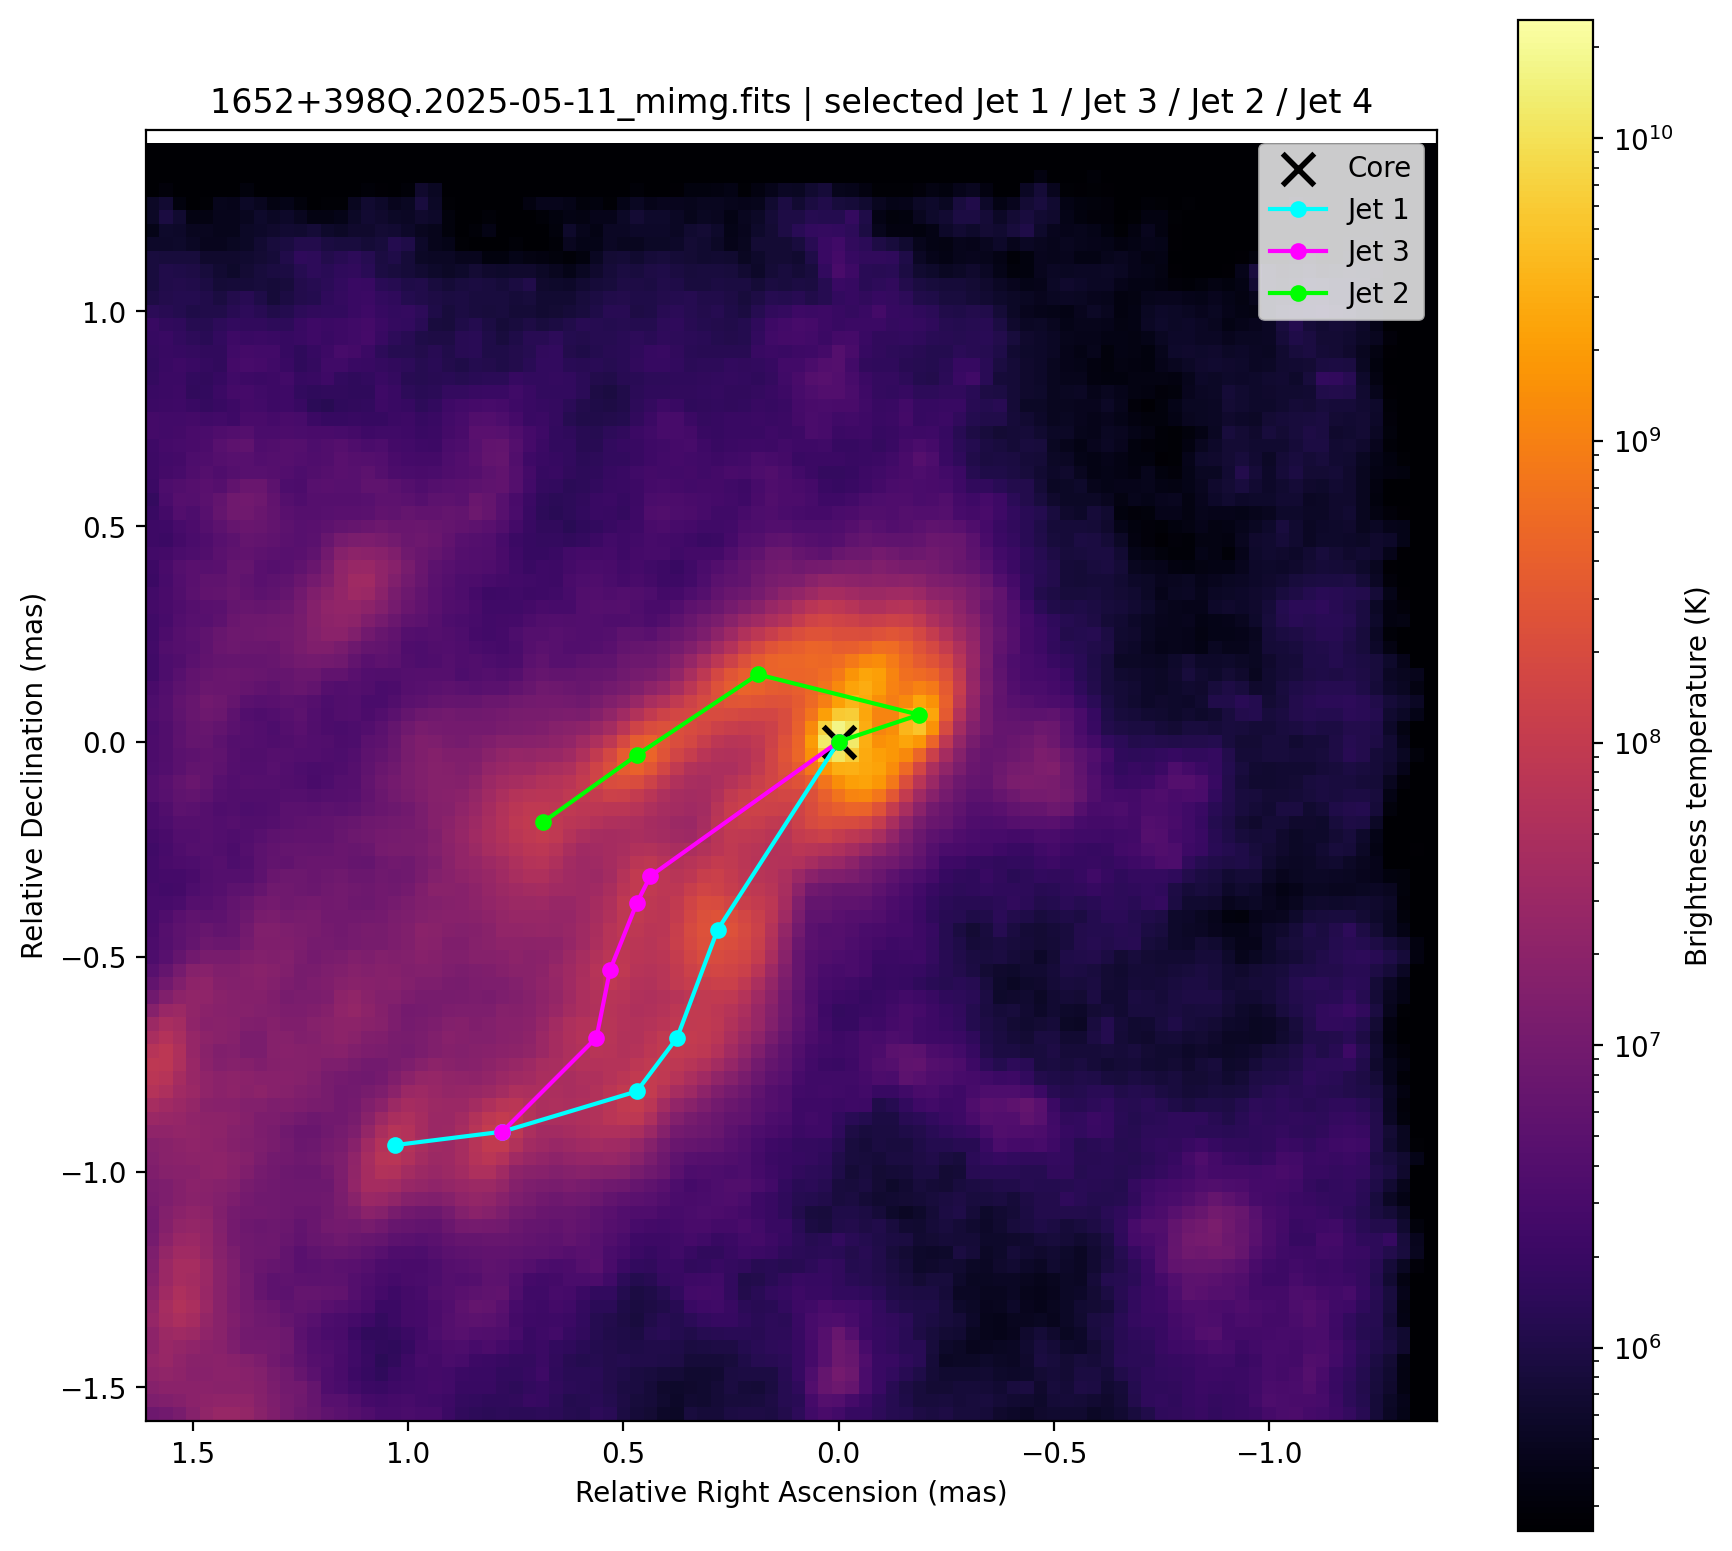

保存先フォルダ: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4


In [36]:
# ============================================================
# 手順3：指定した候補を結んだ画像とCSVを保存・表示
# 番号を変えたら手順2とこのセルだけを再実行する
# ============================================================
if JET1_IDS or JET3_IDS or JET2_IDS or JET4_IDS:
    main(mode="selected")
else:
    print("手順2に候補番号を入力してから、このセルを実行してください")

輝度と距離のグラフを保存: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/jet_tracking_4/2025-05-11_jet_brightness_temperature_vs_distance.png


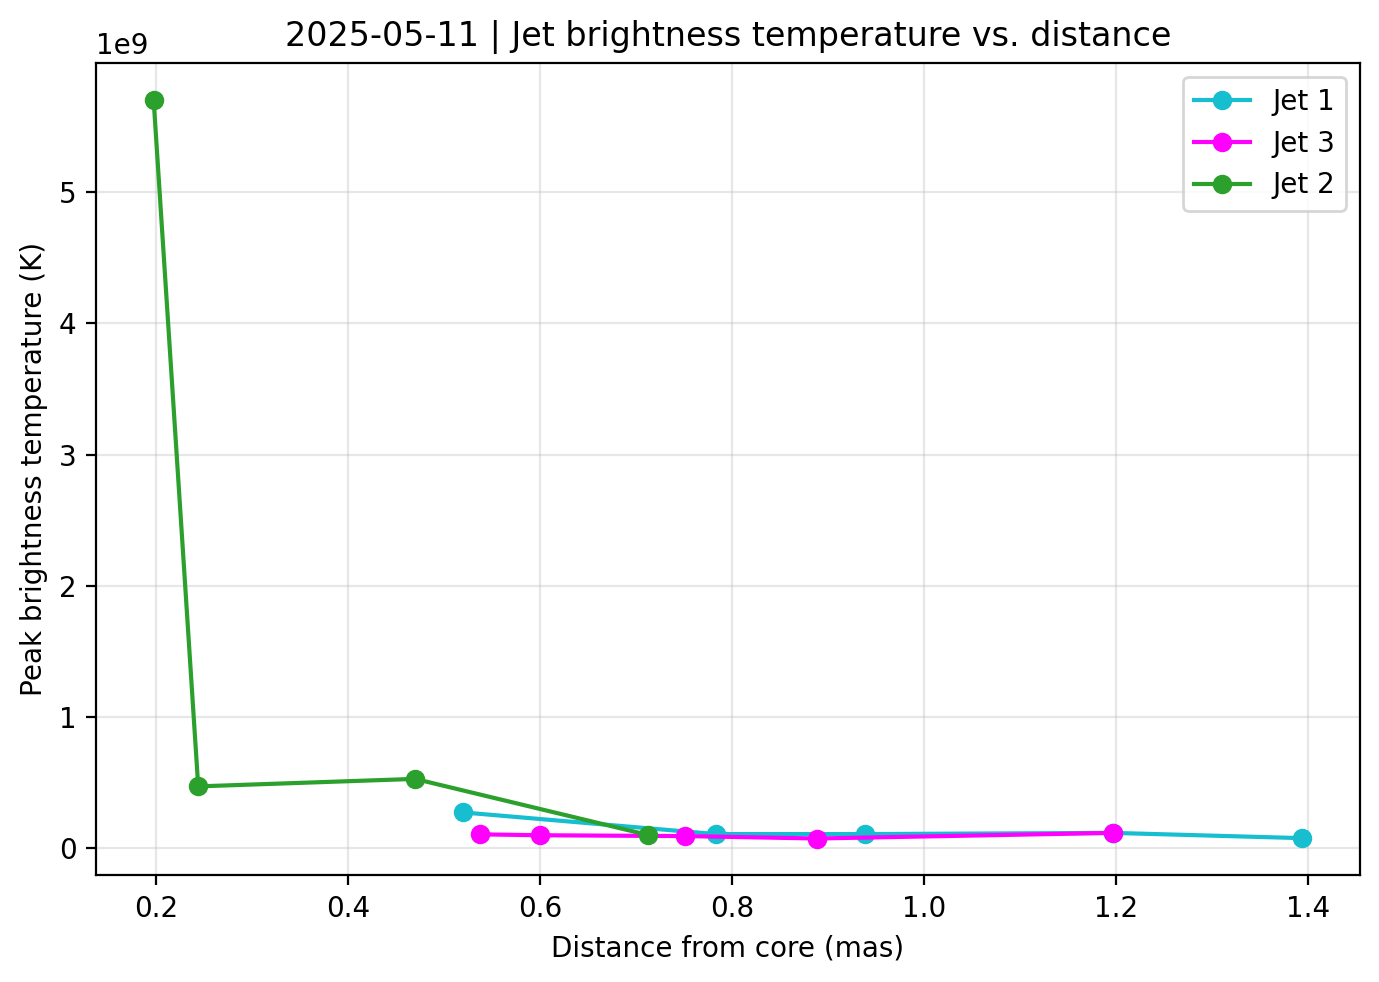

In [38]:
# ============================================================
# 手順4：選択したJet 1・Jet 3・Jet 2・Jet 4の距離とピーク輝度をグラフ化
# 横軸：コアから各候補点までの距離 [mas]
# 縦軸：選択した画素のピーク輝度温度 [K]
# 手順3で保存したCSVから読み込み、画像を保存して表示する
# ============================================================
if not (JET1_IDS or JET3_IDS or JET2_IDS or JET4_IDS):
    print("手順2で候補番号を指定し、手順3を実行してからグラフを作成してください")
else:
    date_match = re.search(r"\d{4}-\d{2}-\d{2}", FITS_FILE.name)
    if date_match is None:
        raise ValueError(
            f"FITSのファイル名から観測日を読み取れません: {FITS_FILE.name}"
        )
    observation_date = date_match.group()

    selected_csv = (
        OUTPUT_DIR / "02_selected_jet_points" / f"{observation_date}.csv"
    )
    if not selected_csv.is_file():
        raise FileNotFoundError(
            f"先に手順3を実行してください: {selected_csv}"
        )

    with selected_csv.open("r", newline="", encoding="utf-8-sig") as f:
        selected_rows = list(csv.DictReader(f))

    # ============================================================
    # 指定した候補番号と保存済みCSVが一致するか確認
    # ============================================================
    expected_ids = {
        "Jet 1": JET1_IDS,
        "Jet 3": JET3_IDS,
        "Jet 2": JET2_IDS,
        "Jet 4": JET4_IDS,
    }

    for jet_name, ids in expected_ids.items():
        csv_ids = [
            int(row["candidate_id"])
            for row in selected_rows
            if row["jet"] == jet_name
        ]
        if csv_ids != ids:
            raise ValueError(
                f"{jet_name}の番号がCSVと一致しません。手順3を再実行してください"
            )

    MIN_DISTANCE_MAS = 0.0  # この距離[mas]より近い点はグラフから除く

    # ============================================================
    # 最大4経路の距離と輝度温度を描画
    # ============================================================
    fig, ax = plt.subplots(figsize=(7, 5))

    jet_colors = {
        "Jet 1": "tab:cyan",
        "Jet 3": "magenta",
        "Jet 2": "tab:green",
        "Jet 4": "orange",
    }

    for jet_name in ("Jet 1", "Jet 3", "Jet 2", "Jet 4"):
        jet_rows = sorted(
            (row for row in selected_rows if row["jet"] == jet_name),
            key=lambda row: int(row["order"]),
        )
        jet_rows = [
            row for row in jet_rows
            if float(row["core_distance_mas"]) >= MIN_DISTANCE_MAS
        ]
        if not jet_rows:
            continue

        distance_mas = [
            float(row["core_distance_mas"]) for row in jet_rows
        ]
        temperature_K = [
            float(row["peak_brightness_temperature_K"])
            for row in jet_rows
        ]

        ax.plot(
            distance_mas,
            temperature_K,
            "-o",
            color=jet_colors[jet_name],
            linewidth=1.5,
            markersize=6,
            label=jet_name,
        )

    ax.set_xlabel("Distance from core (mas)")
    ax.set_ylabel("Peak brightness temperature (K)")
    ax.set_title(
        f"{observation_date} | Jet brightness temperature vs. distance"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    # ============================================================
    # グラフを保存してNotebook内に表示
    # ============================================================
    graph_png = (
        OUTPUT_DIR
        / f"{observation_date}_jet_brightness_temperature_vs_distance.png"
    )
    fig.savefig(graph_png, dpi=200, bbox_inches="tight")
    plt.close(fig)

    print(f"輝度と距離のグラフを保存: {graph_png.resolve()}")
    display(Image(filename=str(graph_png), width=700))